In [1]:
import numpy as np
from scipy import interpolate
import matplotlib.pyplot as plt

In [2]:
# Physiologically acceptable range of HR and distances between R.
# Signals outside of it are treated like acquisition error and filtered out.
PHYSIO_HR = np.array([30, 200])
PHYSIO_RR = (60 / PHYSIO_HR)[::-1]
PHYSIO_RR

array([0.3, 2. ])

In [3]:
# Raw = not-filtered
RR_raw_chf = np.loadtxt("data/chf206.dat")

print(f"{RR_raw_chf.shape=}")

RR_raw_chf.shape=(135470,)


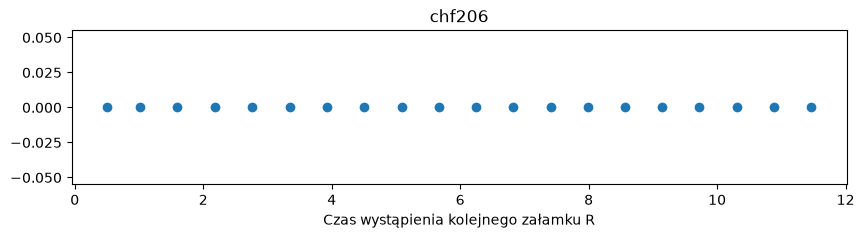

In [4]:
# Calculate cumsum BEFORE filtering, to keep correct timings
RR_chf_t_raw = np.cumsum(RR_raw_chf)

fragment_len = 20
plt.figure(figsize=(10, 2))
plt.scatter(RR_chf_t_raw[:fragment_len], np.zeros(fragment_len))
plt.xlabel("Czas wystąpienia kolejnego załamku R")
plt.title("chf206")
plt.show()

In [5]:
RR_raw_chf.min(), RR_raw_chf.max()

(np.float64(0.25), np.float64(20.242))

In [6]:
# Filter out non-physiological
chf_physio_idx = (RR_raw_chf >= PHYSIO_RR[0]) & (RR_raw_chf <= PHYSIO_RR[1])
RR_chf = RR_raw_chf[chf_physio_idx]
RR_chf_t = RR_chf_t_raw[chf_physio_idx]

print(f"Filtered: {RR_raw_chf.shape[0]-RR_chf.shape[0]}")

RR_chf.shape

Filtered: 28


(135442,)

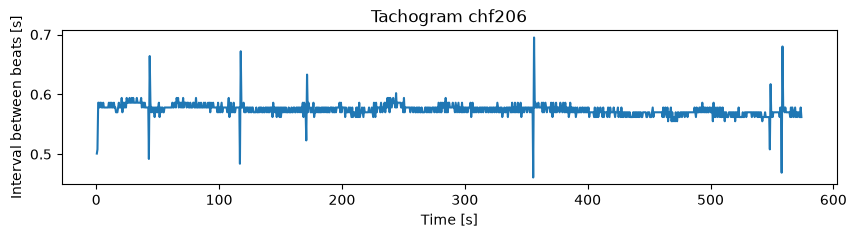

In [7]:
plt.figure(figsize=(10, 2))
fragment_len = 1000
plt.plot(RR_chf_t[:fragment_len], RR_chf[:fragment_len])
plt.xlabel("Time [s]")
plt.ylabel("Interval between beats [s]")
plt.title("Tachogram chf206")
plt.show()

In [8]:
RR_raw_nsr = np.loadtxt("data/nsr001.dat")

print(f"{RR_raw_nsr.shape=}")

RR_raw_nsr.shape=(106460,)


In [9]:
RR_raw_nsr.min(), RR_raw_nsr.max()

(np.float64(0.305), np.float64(7.477))

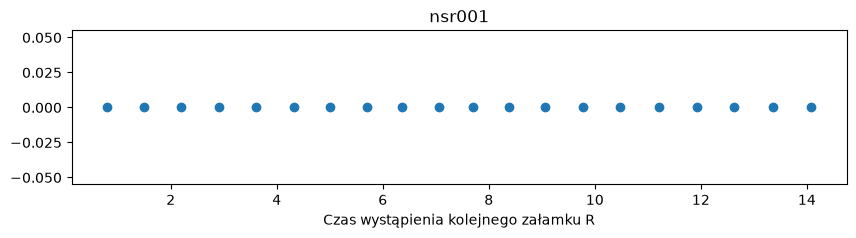

In [10]:
RR_nsr_t_raw = np.cumsum(RR_raw_nsr)

fragment_len = 20
plt.figure(figsize=(10, 2))
plt.scatter(RR_nsr_t_raw[:fragment_len], np.zeros(fragment_len))
plt.xlabel("Czas wystąpienia kolejnego załamku R")
plt.title("nsr001")
plt.show()

In [11]:
# Filter out non-physiological
nsr_physio_idx = (RR_raw_nsr >= PHYSIO_RR[0]) & (RR_raw_nsr <= PHYSIO_RR[1])
RR_nsr = RR_raw_nsr[nsr_physio_idx]
RR_nsr_t = RR_nsr_t_raw[nsr_physio_idx]

print(f"Filtered: {RR_raw_nsr.shape[0]-RR_nsr.shape[0]}")

RR_nsr.shape

Filtered: 3


(106457,)

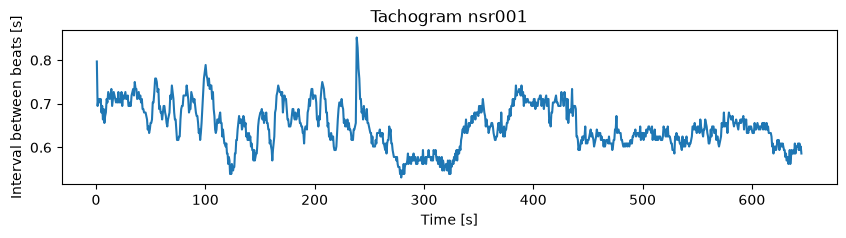

In [12]:
fragment_len = 1000
plt.figure(figsize=(10, 2))
plt.plot(RR_nsr_t[:fragment_len], RR_nsr[:fragment_len])
plt.xlabel("Time [s]")
plt.ylabel("Interval between beats [s]")
plt.title("Tachogram nsr001")
plt.show()

In [13]:
f_vec = np.linspace(0.001, 0.5, 1000)

In [14]:
def P(t, x, f):
    return (np.sum(x * np.cos(2 * np.pi * f * t))**2 + np.sum(x * np.sin(2 * np.pi * f * t))**2) / len(x)


def P_LS(t, x, f) -> float:
    if f == 0:
        return 0.0

    num_tau = np.sum(np.sin(4 * np.pi * f * t))
    den_tau = np.sum(np.cos(4 * np.pi * f * t))
    tau = (1 / (4 * np.pi * f)) * np.arctan2(num_tau, den_tau)

    t_tau = t - tau

    cos_term = np.sum(x * np.cos(2 * np.pi * f * t_tau))
    sin_term = np.sum(x * np.sin(2 * np.pi * f * t_tau))

    sum_cos_sq = np.sum(np.cos(2 * np.pi * f * t_tau) ** 2)
    sum_sin_sq = np.sum(np.sin(2 * np.pi * f * t_tau) ** 2)

    if sum_cos_sq == 0 or sum_sin_sq == 0:
        return 0.0

    pls = 0.5 * ((cos_term ** 2 / sum_cos_sq) + (sin_term ** 2 / sum_sin_sq))
    return pls


def calc_periodogram(t, x, method) -> np.ndarray:
    x = x - np.mean(x)

    if method == "classic":
        per = np.array([P(t, x, f_one) for f_one in f_vec])
    elif method == "lombscargle":
        per = np.array([P_LS(t, x, f_one) for f_one in f_vec])
    else:
        raise NotImplementedError

    return per

In [15]:
periodogram_classic = calc_periodogram(RR_chf_t, RR_chf, method="classic")
periodogram_ls = calc_periodogram(RR_chf_t, RR_chf, method="lombscargle")

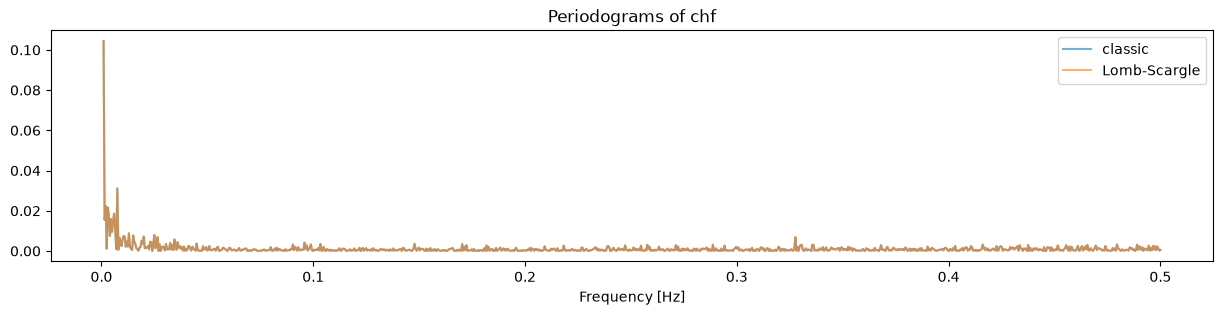

In [16]:
plt.figure(figsize=(15, 3))
plt.title("Periodograms of chf")
plt.plot(f_vec, periodogram_classic, label="classic", alpha=0.6)
plt.plot(f_vec, periodogram_ls, label="Lomb-Scargle", alpha=0.6)
plt.xlabel("Frequency [Hz]")
plt.legend()
plt.show()

In [17]:
print(f"Duration: {RR_chf_t[-1]:.2f} s")
print(f"Duration: {RR_chf_t[-1] / 60:.2f} min")
print(f"Frequency resolution: {1 / RR_chf_t[-1]:.6f} Hz")

Duration: 75215.84 s
Duration: 1253.60 min
Frequency resolution: 0.000013 Hz


## Spectrum via interpolation

The tachogram is resampled onto an even 4 Hz grid (the usual choice for HRV) with nearest-neighbour, linear and cubic-spline interpolation. The classic periodogram (1) is then computed on the evenly sampled signal.

All spectra are scaled to a one-sided PSD in ms²/Hz: `PSD = 2 * P / fs * 1e6`, where `fs` is the sampling rate (4 Hz after interpolation, or the mean beat rate `N / T` for unevenly sampled data). With this scaling, the area under the PSD equals the signal variance, so band powers come out in ms².

In [18]:
FS_INTERP = 4.0  # Hz


def interpolate_rr(t, rr, kind):
    t_eq = np.arange(t[0], t[-1], 1 / FS_INTERP)
    rr_eq = interpolate.interp1d(t, rr, kind=kind)(t_eq)
    return t_eq, rr_eq


def to_psd(periodogram, fs):
    """Periodogram -> one-sided PSD in ms^2/Hz (RR given in seconds)."""
    return 2 * periodogram / fs * 1e6


def compute_psds(t, rr) -> dict:
    fs_mean = len(t) / (t[-1] - t[0])
    psds = {
        "classic (uneven)": to_psd(calc_periodogram(t, rr, method="classic"), fs_mean),
        "Lomb-Scargle": to_psd(calc_periodogram(t, rr, method="lombscargle"), fs_mean),
    }
    for kind, label in [("nearest", "interp. nearest"), ("linear", "interp. linear"), ("cubic", "interp. spline")]:
        t_eq, rr_eq = interpolate_rr(t, rr, kind)
        psds[label] = to_psd(calc_periodogram(t_eq, rr_eq, method="classic"), FS_INTERP)
    return psds

In [19]:
# Takes ~1.5 min: every method evaluates 1000 frequencies over ~100k beats / ~350k samples
psds_nsr = compute_psds(RR_nsr_t, RR_nsr)
psds_chf = compute_psds(RR_chf_t, RR_chf)

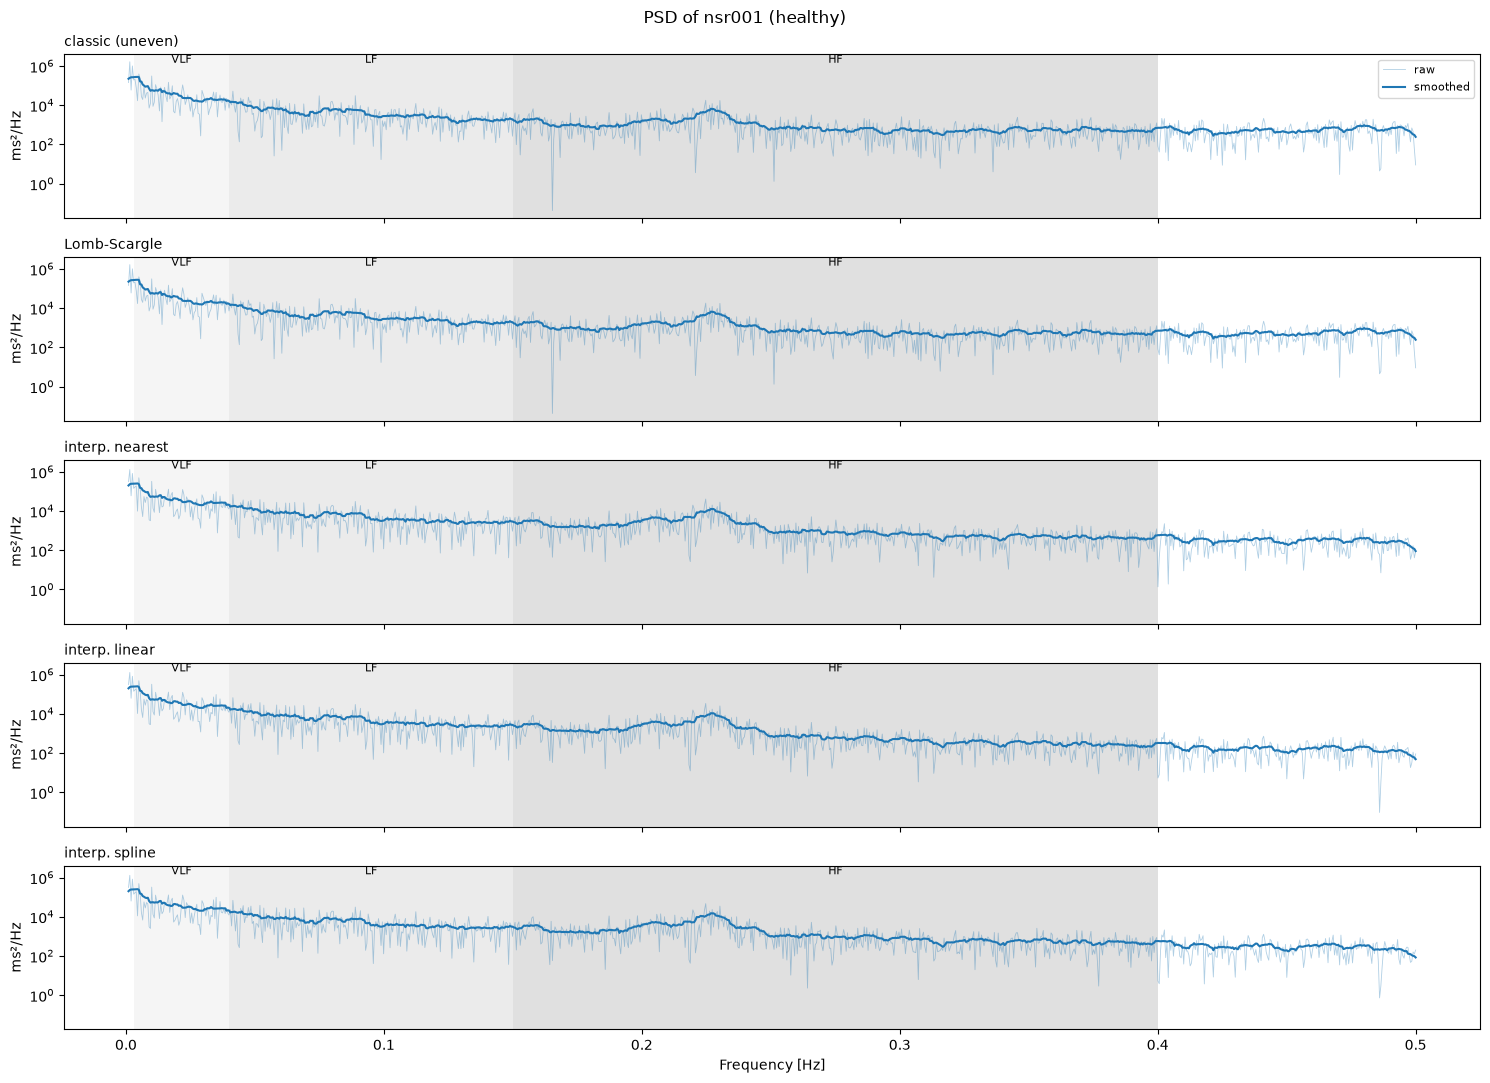

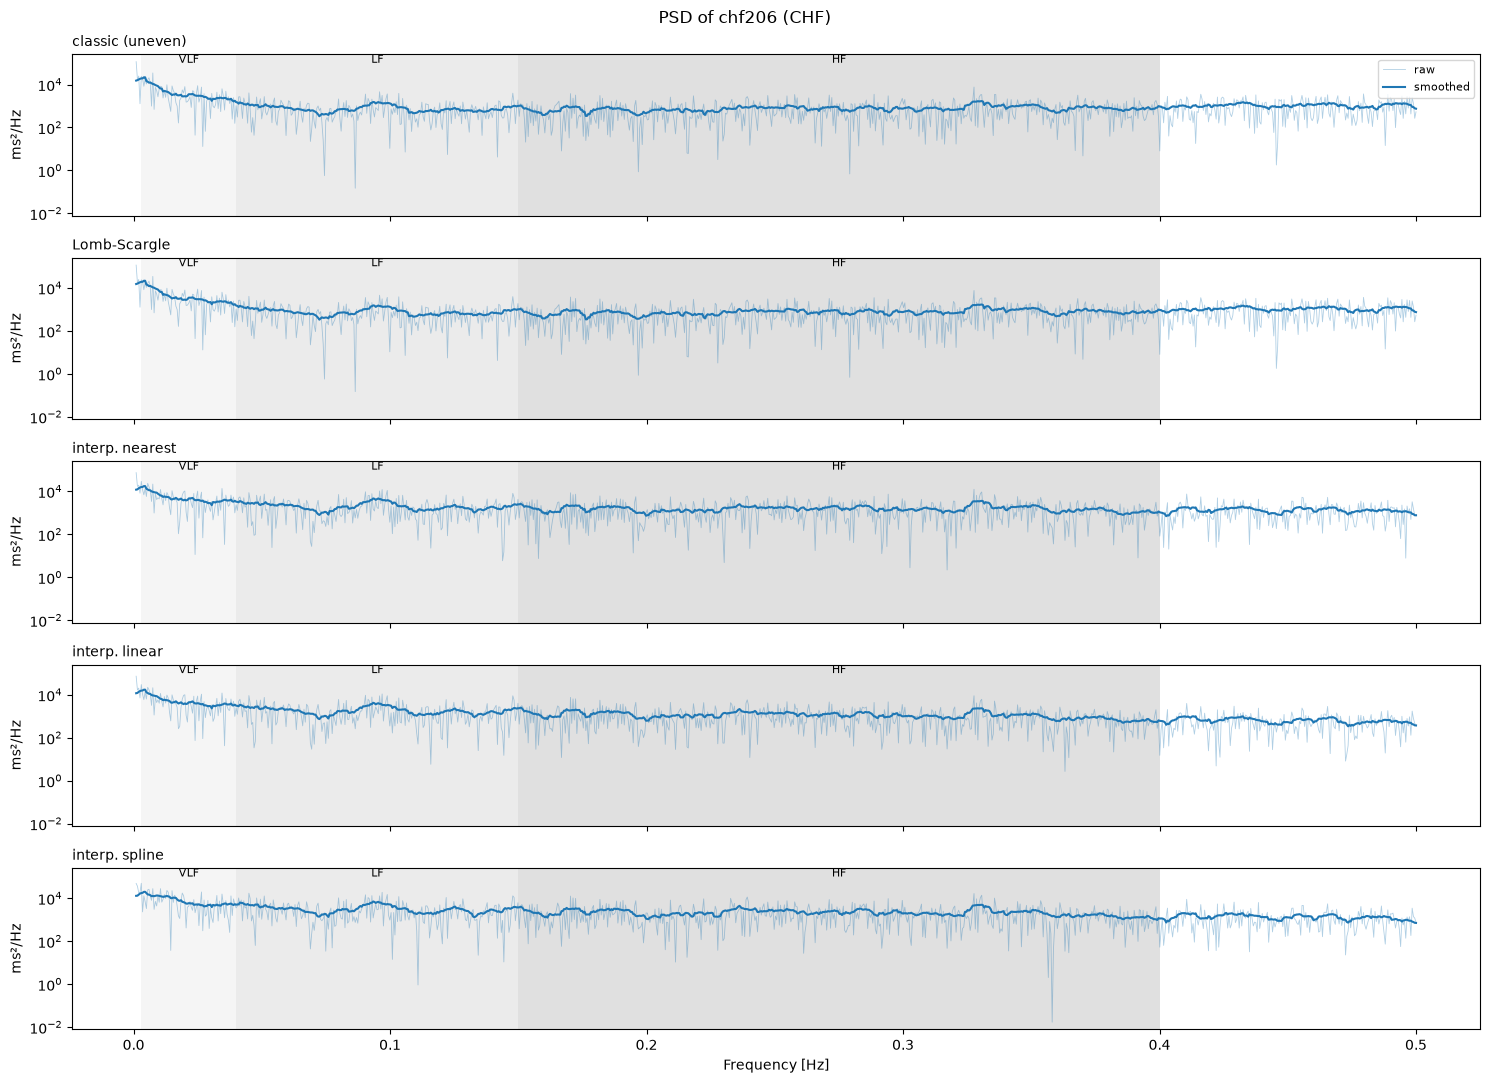

In [20]:
BANDS = {
    "VLF": (0.003, 0.04),
    "LF": (0.04, 0.15),
    "HF": (0.15, 0.4),
}


def plot_psds(psds, title):
    fig, axes = plt.subplots(len(psds), 1, figsize=(15, 2.2 * len(psds)), sharex=True, sharey=True)
    for ax, (method, psd) in zip(axes, psds.items()):
        for (band, (lo, hi)), shade in zip(BANDS.items(), [0.04, 0.08, 0.12]):
            ax.axvspan(lo, hi, color="black", alpha=shade, lw=0)
            ax.text((lo + hi) / 2, 1, band, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)
        smooth = np.convolve(psd, np.ones(15) / 15, mode="same")  # 15-bin moving average, display only
        ax.semilogy(f_vec, psd, lw=0.6, alpha=0.35, label="raw")
        ax.semilogy(f_vec, smooth, lw=1.5, color="tab:blue", label="smoothed")
        ax.set_ylabel("ms²/Hz")
        ax.set_title(method, loc="left", fontsize=10)
    axes[0].legend(loc="upper right", fontsize=8)
    axes[-1].set_xlabel("Frequency [Hz]")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_psds(psds_nsr, "PSD of nsr001 (healthy)")
plot_psds(psds_chf, "PSD of chf206 (CHF)")

## HRV parameters in the frequency domain

Bands follow the Task Force (1996) definitions: VLF 0.003–0.04 Hz, LF 0.04–0.15 Hz, HF 0.15–0.4 Hz. TP is the power from 0.003 to 0.4 Hz, i.e. VLF + LF + HF. The ULF band (< 0.003 Hz) is left out because the frequency grid starts at 0.001 Hz.

LFnu and HFnu are the normalized units: LF or HF divided by (LF + HF).

In [21]:
def band_power(psd, lo, hi):
    mask = (f_vec >= lo) & (f_vec < hi)
    return np.trapezoid(psd[mask], f_vec[mask])


def hrv_params(psd) -> dict:
    p = {band: band_power(psd, lo, hi) for band, (lo, hi) in BANDS.items()}
    p["TP"] = p["VLF"] + p["LF"] + p["HF"]
    p["LF/HF"] = p["LF"] / p["HF"]
    p["LFnu"] = 100 * p["LF"] / (p["LF"] + p["HF"])
    p["HFnu"] = 100 * p["HF"] / (p["LF"] + p["HF"])
    return p


def print_hrv_table(psds, name):
    print(f"{name}  (powers in ms², nu in %)")
    print(f"{'method':18s}{'TP':>9s}{'VLF':>9s}{'LF':>9s}{'HF':>9s}{'LF/HF':>8s}{'LFnu':>7s}{'HFnu':>7s}")
    for method, psd in psds.items():
        p = hrv_params(psd)
        print(f"{method:18s}{p['TP']:9.0f}{p['VLF']:9.0f}{p['LF']:9.0f}{p['HF']:9.0f}{p['LF/HF']:8.2f}{p['LFnu']:7.1f}{p['HFnu']:7.1f}")
    print()


print_hrv_table(psds_nsr, "nsr001")
print_hrv_table(psds_chf, "chf206")

nsr001  (powers in ms², nu in %)
method                   TP      VLF       LF       HF   LF/HF   LFnu   HFnu
classic (uneven)       2270     1531      482      258    1.87   65.2   34.8
Lomb-Scargle           2270     1530      482      258    1.87   65.2   34.8
interp. nearest        2756     1675      650      432    1.51   60.1   39.9
interp. linear         2662     1676      631      355    1.78   64.0   36.0
interp. spline         2835     1682      660      493    1.34   57.3   42.7

chf206  (powers in ms², nu in %)
method                   TP      VLF       LF       HF   LF/HF   LFnu   HFnu
classic (uneven)        449      166       89      195    0.46   31.3   68.7
Lomb-Scargle            449      166       89      195    0.46   31.3   68.7
interp. nearest         814      188      232      394    0.59   37.1   62.9
interp. linear          690      185      215      289    0.74   42.6   57.4
interp. spline         1195      285      362      547    0.66   39.9   60.1



In [22]:
# Sanity check of the PSD scaling: the area under the PSD up to Nyquist (~0.5 Hz) should be
# the variance of RR minus the ULF part (< 0.001 Hz, the 24h trend), which falls outside f_vec.
for name, rr, psds in [("nsr001", RR_nsr, psds_nsr), ("chf206", RR_chf, psds_chf)]:
    print(f"{name}: var(RR) = {np.var(rr) * 1e6:.0f} ms², "
          f"PSD area 0.001-0.5 Hz = {band_power(psds['Lomb-Scargle'], 0, 0.5):.0f} ms², "
          f"mean HR = {60 / np.mean(rr):.1f} bpm")

nsr001: var(RR) = 28442 ms², PSD area 0.001-0.5 Hz = 3871 ms², mean HR = 78.9 bpm
chf206: var(RR) = 2317 ms², PSD area 0.001-0.5 Hz = 624 ms², mean HR = 108.2 bpm


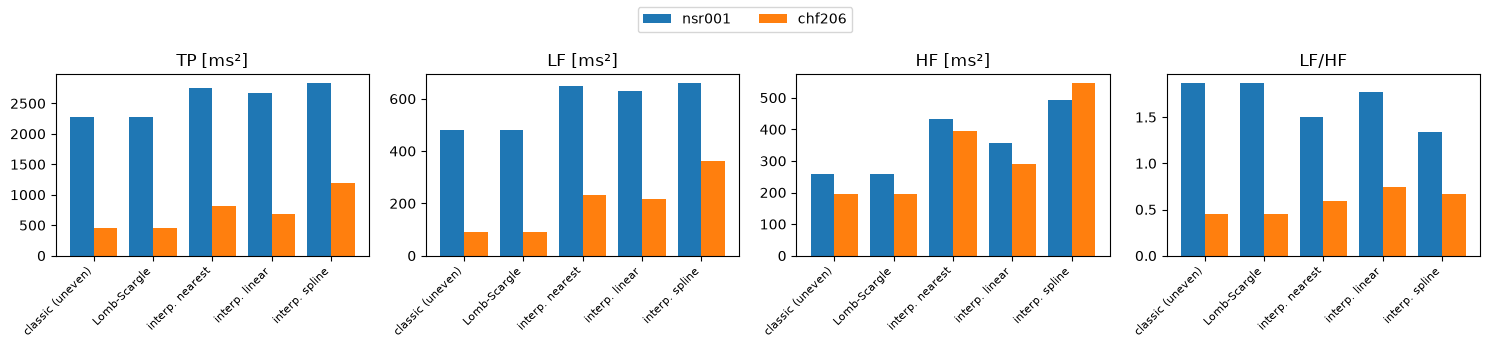

In [23]:
methods = list(psds_nsr)
x = np.arange(len(methods))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, param in zip(axes, ["TP", "LF", "HF", "LF/HF"]):
    ax.bar(x - 0.2, [hrv_params(psds_nsr[m])[param] for m in methods], 0.4, label="nsr001")
    ax.bar(x + 0.2, [hrv_params(psds_chf[m])[param] for m in methods], 0.4, label="chf206")
    ax.set_title(param + ("" if param == "LF/HF" else " [ms²]"))
    ax.set_xticks(x, methods, rotation=45, ha="right", fontsize=8)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

## Comparison and interpretation

**Methods.** Lomb–Scargle and the classic periodogram on the unevenly sampled data give almost identical band powers. These are the reference values, because they work on the true beat times. Interpolation adds power, mostly in HF, and the amount depends on the method:
- nearest-neighbour produces a staircase whose jumps add broadband high-frequency energy;
- cubic spline overshoots around artefacts and ectopic beats, so it inflates power the most;
- linear interpolation is the closest to Lomb–Scargle, but it still acts as a low-pass filter and adds some distortion.

The effect is much stronger for chf206, whose tachogram contains more irregular and ectopic beats.

**nsr001 vs chf206.**
- *Total variability.* The CHF patient's total power is about 5× lower, and the RR variance is about 12× lower. Overall HRV is strongly reduced, which is a typical finding in heart failure and a known adverse prognostic marker. The patient's resting HR is also higher (about 108 vs 79 bpm), which points to sympathetic activation.
- *LF.* LF falls from about 480 to about 90 ms². Loss of LF power is characteristic of advanced CHF (NYHA III): the baroreflex modulation is depressed.
- *LF/HF.* The ratio drops from about 1.9 to about 0.5. In the healthy subject LF dominates over HF, as expected for a 24 h recording. In chf206 HF dominates, so the ratio no longer works as a "sympatho-vagal balance" index. The residual "HF" power in CHF probably comes partly from irregular and ectopic beats rather than real respiratory sinus arrhythmia. Only non-physiological RR intervals were filtered out here, not ectopic beats. The spectra back this up. nsr001 has a clear respiratory peak at about 0.23 Hz, while chf206's spectrum above about 0.05 Hz is flat and noise-like, with no peak.
- *VLF.* VLF is also about 9× lower in CHF. Low VLF power is among the strongest predictors of mortality in heart failure.

Caveat: the spectra cover whole 24 h recordings, so they mix day and night. A strict short-term analysis would average 5-min segments.